# Forced photometry of SN 2023zkd

SN 2023zkd ([Gagliano et al. 2025](https://arxiv.org/abs/2502.19469)) is a double-peaked, helium-rich Type IIn supernova at $z \approx 0.056$, discovered by ZTF on 2023 July 7 (MJD 60132.5). Using difference-image forced photometry, the authors revealed years of precursor emission, which is exactly the kind of measurement `ztforce` can enable.

Here, we demonstrate how `ztforce` can reveal the precursor emission for this object.

**Setup:** `pip install ztforce` and set your IRSA credentials (see the [docs](https://ztforce.readthedocs.io)).


## 1. The target

The position from the paper, in decimal degrees:

In [1]:
from astropy.coordinates import SkyCoord

coord = SkyCoord("15h48m47.536s", "+09d12m00.28s", frame="icrs")
RA, DEC = float(coord.ra.deg), float(coord.dec.deg)
print(f"RA = {RA:.5f} deg, Dec = {DEC:.5f} deg")

RA = 237.19807 deg, Dec = 9.20008 deg


Before measuring anything, look at the field. `ztforce` downloads IRSA science-image cutouts centred on the target for every epoch it measures; here we fetch two r-band cutouts by hand with the same functions, one from 2018, before the explosion, and one near the supernova's peak. The red ticks mark the position above; the faint smudge there in 2018 is the host galaxy, PSO J154847.495+091200.90, whose nucleus lies 0.9″ from the supernova.

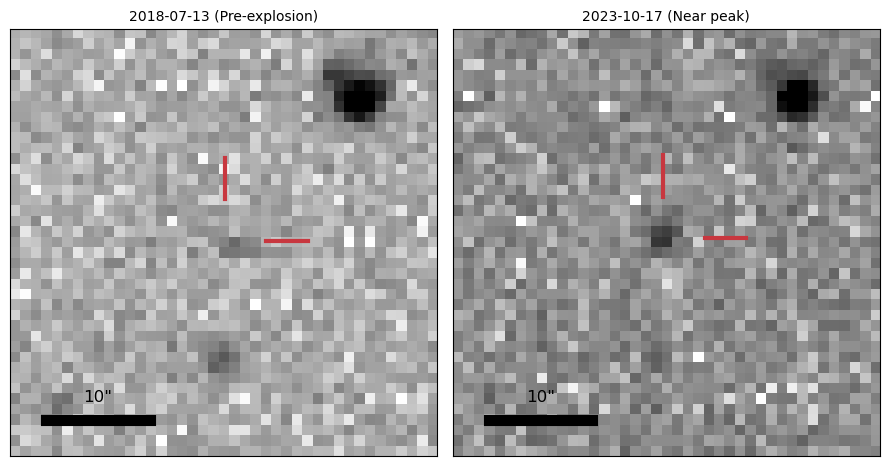

In [2]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
from astropy.time import Time
from astropy.visualization import AsinhStretch, ImageNormalize, PercentileInterval
from ztforce import build_config
from ztforce.image import ZTFImage
from ztforce.ztf_images import build_sci_url, download_fits, query_sci_metadata_bands

MJD_OFFSET = 2400000.5
DISCOVERY_MJD = 60132.5

config = build_config()  # reads your IRSA credentials
meta = query_sci_metadata_bands(RA, DEC, ["r"], config)["r"]  # every r-band exposure covering the position
good = meta[(meta["infobits"] == 0) & (meta["seeing"] < 2.2)]
mjd = good["obsjd"] - MJD_OFFSET
epochs = {
    "Pre-explosion": good[(mjd > 58150) & (mjd < 58400)].nsmallest(1, "seeing").iloc[0],
    "Near peak": good[(mjd > DISCOVERY_MJD + 60) & (mjd < DISCOVERY_MJD + 130)]
    .nsmallest(1, "seeing")
    .iloc[0],
}

cutout_dir = Path(tempfile.gettempdir()) / "ztforce_sn2023zkd"
HALF = 20  # half-width of the displayed stamp in pixels (1 px = 1.01")
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, (label, row) in zip(axes, epochs.items(), strict=True):
    path = cutout_dir / f"{label.split()[0].lower()}_r.fits"
    if not path.exists():
        download_fits(build_sci_url(row, RA, DEC, cutout_size_arcmin=1.0), path, config)
    img = ZTFImage(str(path), "r", config)
    x, y = img.sky_to_pixel(coord)
    x0, y0 = int(round(x)) - HALF, int(round(y)) - HALF
    stamp = img.data[y0 : y0 + 2 * HALF + 1, x0 : x0 + 2 * HALF + 1]
    norm = ImageNormalize(stamp, interval=PercentileInterval(99.3), stretch=AsinhStretch(0.05))
    ax.imshow(
        stamp,
        origin="lower",
        cmap="gray_r",
        norm=norm,
        extent=(x0 - 0.5, x0 + 2 * HALF + 0.5, y0 - 0.5, y0 + 2 * HALF + 0.5),
    )
    ax.plot([x + 4, x + 8], [y, y], color="#c8373f", lw=3)
    ax.plot([x, x], [y + 4, y + 8], color="#c8373f", lw=3)
    scale = float(img.header["PIXSCALE"])
    ax.plot([x0 + 3, x0 + 3 + 10 / scale], [y0 + 3, y0 + 3], color="k", lw=8)
    ax.text(x0 + 3 + 5 / scale, y0 + 4.5, '10"', ha="center", va="bottom", fontsize=12)
    date = Time(img.obs_jd, format="jd").iso[:10]
    ax.set_title(f"{date} ({label})", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()

## 2. Run forced photometry

One call measures every ZTF g-, r- and i-band exposure covering the position (over 2,000 here, so the first run takes a while; results are cached). Failed downloads are kept as flagged rows and retried on the next call.

In [3]:
from ztforce import run_forced_photometry

lcs = run_forced_photometry(ra=RA, dec=DEC, bands=["g", "r", "i"], show_progress=True)
lcs

/var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/ipykernel_59426/1957409929.py:3: UserWarning: (237.19807, 9.20008): epochs not measured: 41 failed. They are kept as flagged rows; failed downloads are retried on the next run.
  lcs = run_forced_photometry(ra=RA, dec=DEC, bands=["g", "r", "i"], show_progress=True)


{'g': Lightcurve(ra=237.19807, dec=9.20008, n_epochs=828, bands=['g']),
 'r': Lightcurve(ra=237.19807, dec=9.20008, n_epochs=1354, bands=['r']),
 'i': Lightcurve(ra=237.19807, dec=9.20008, n_epochs=389, bands=['i'])}

`.df` has one row per exposure. `flux`/`flux_err` are kept at any S/N; `mag`/`mag_err` only for detections (S/N ≥ 3), with a 5σ `upper_limit` otherwise. `flags` is a quality bitmask, 0 = good (use `df["flags"]`, since `df.flags` is a pandas attribute).

In [4]:
import pandas as pd

summary = []
for band, lc in lcs.items():
    df = lc.df
    summary.append(
        dict(
            band=band,
            epochs=len(df),
            good=int((df["flags"] == 0).sum()),
            detections=int(df["detection"].sum()),
            first_mjd=round(df["obsjd"].min() - MJD_OFFSET, 1),
            last_mjd=round(df["obsjd"].max() - MJD_OFFSET, 1),
        )
    )
pd.DataFrame(summary).set_index("band")

,epochs,good,detections,first_mjd,last_mjd
band,,,,,
g,828,707,483,58204.4,61284.2
r,1354,1152,851,58198.4,61284.2
i,389,347,173,58228.5,61288.1


In [5]:
lcs["r"].df[["obsjd", "flux", "flux_err", "mag", "mag_err", "snr", "detection", "upper_limit", "flags"]].tail(
    8
)

,obsjd,flux,flux_err,mag,mag_err,snr,detection,upper_limit,flags
1346,2.461264e+06,62.160774,28.873989,NaN,NaN,2.152829,False,20.676833,0
1347,2.461265e+06,80.930369,24.922021,21.397609,0.334346,3.247344,True,NaN,0
1348,2.461268e+06,94.859877,22.036340,21.307314,0.252221,4.304702,True,NaN,0
1349,2.461270e+06,61.978171,22.398143,NaN,NaN,2.767112,False,21.145165,0
1350,2.461276e+06,109.782333,31.644084,21.127074,0.312957,3.469285,True,NaN,0
1351,2.461278e+06,64.616031,48.354161,NaN,NaN,1.336308,False,20.123627,0
1352,2.461279e+06,91.937868,35.658743,NaN,NaN,2.578270,False,20.544781,0
1353,2.461285e+06,144.720525,44.345564,20.813697,0.332694,3.263472,True,NaN,0


## 3. Plot the lightcurve

Detections with error bars, good non-detections as 5σ upper limits. The lower panel zooms on the supernova; the dashed line marks discovery.

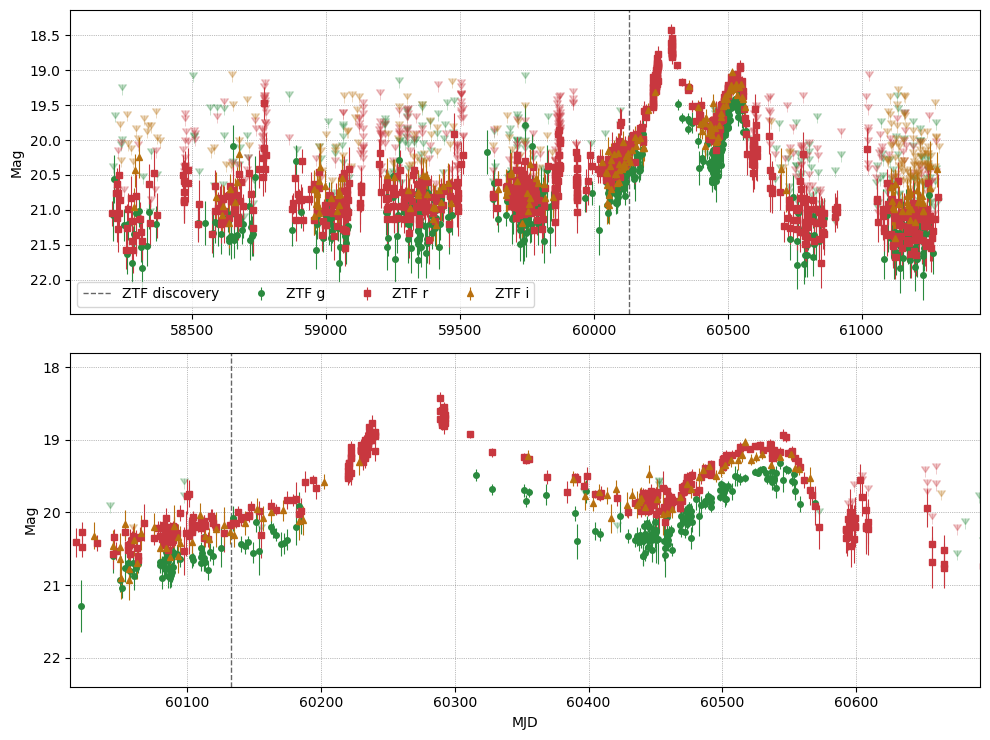

In [6]:
import numpy as np

BAND_STYLE = {
    "g": dict(color="#2a8a3e", marker="o"),
    "r": dict(color="#c8373f", marker="s"),
    "i": dict(color="#b8700f", marker="^"),
}


def plot_lightcurve(ax, df, band, label):
    """Detections as points, good non-detections as downward arrows."""
    style = BAND_STYLE[band]
    mjd = df["obsjd"] - MJD_OFFSET
    det = df["detection"]
    lim = (df["flags"] == 0) & ~det & np.isfinite(df["upper_limit"])
    ax.errorbar(
        mjd[det],
        df.loc[det, "mag"],
        yerr=df.loc[det, "mag_err"],
        fmt=style["marker"],
        ms=4,
        lw=0.8,
        color=style["color"],
        label=label,
    )
    ax.errorbar(
        mjd[lim],
        df.loc[lim, "upper_limit"],
        yerr=0.15,
        uplims=True,
        fmt="none",
        lw=0.6,
        color=style["color"],
        alpha=0.3,
    )


fig, (ax_all, ax_sn) = plt.subplots(2, 1, figsize=(10, 7.5), gridspec_kw=dict(height_ratios=[1, 1.1]))
for band, lc in lcs.items():
    plot_lightcurve(ax_all, lc.df, band, f"ZTF {band}")
    plot_lightcurve(ax_sn, lc.df, band, f"ZTF {band}")
for ax in (ax_all, ax_sn):
    ax.axvline(DISCOVERY_MJD, color="0.4", ls="--", lw=1, label="ZTF discovery")
    ax.invert_yaxis()
    ax.set_ylabel("Mag")
    ax.grid(ls=":", lw=0.5, color="k", alpha=0.5)
ax_all.legend(loc="lower left", ncol=4)
ax_sn.set_xlim(DISCOVERY_MJD - 120, DISCOVERY_MJD + 560)
ax_sn.set_ylim(22.4, 17.8)
ax_sn.set_xlabel("MJD")
plt.tight_layout()
plt.show()

ztforce measures science images, not difference images, so each point includes the host galaxy's light. Recovering the sub-threshold precursor would need stacking (Section 6) and a host subtraction.

## 4. Compare with ZTF DR24 photometry

The [ZTF DR24 lightcurves](https://irsa.ipac.caltech.edu/docs/program_interface/ztf_lightcurve_api.html) hold the pipeline's PSF-fit photometry for every detected source, using the same pixels, PSF model and zero point as ztforce. The one difference is that the catalog fit lets the source position float while ztforce holds it fixed, so the two should agree closely wherever DR24 has an epoch. `ztfquery` (installed with ztforce) queries them:

In [7]:
from ztfquery import lightcurve

cat = lightcurve.LCQuery.from_position(RA, DEC, 5).data  # radius in arcsec
cat = cat[cat["catflags"] == 0].copy()
cat["band"] = cat["filtercode"].str[1]  # "zg" -> "g"
cat["obsjd"] = cat["mjd"] + MJD_OFFSET
for col in ("ccdid", "qid"):  # the API returns these as hex strings
    cat[col] = cat[col].apply(lambda v: int(str(v), 16))
cat["field"] = cat["field"].astype(int)
cat = cat[cat["band"].isin(lcs)]
cat.groupby("band").size().rename("DR24 epochs")

band
g    316
i     90
r    496
Name: DR24 epochs, dtype: int64

Match each DR24 epoch to the ztforce row from the same exposure (same field, CCD, quadrant, and time to within 5 s):

In [8]:
matched = {}
for band, lc in lcs.items():
    ours = lc.df.sort_values("obsjd")
    theirs = cat[cat["band"] == band].sort_values("obsjd")[
        ["obsjd", "mag", "magerr", "field", "ccdid", "qid"]
    ]
    m = pd.merge_asof(
        ours,
        theirs,
        on="obsjd",
        by=["field", "ccdid", "qid"],
        tolerance=5 / 86400,
        direction="nearest",
        suffixes=("", "_ztf"),
    )
    matched[band] = m[np.isfinite(m["mag_ztf"])]
    n_det = int(matched[band]["detection"].sum())
    print(
        f"{band}: {len(theirs)} DR24 epochs, {len(matched[band])} matched to a ztforce epoch, "
        f"{n_det} of which ztforce also calls detections"
    )

g: 316 DR24 epochs, 316 matched to a ztforce epoch, 303 of which ztforce also calls detections
r: 496 DR24 epochs, 496 matched to a ztforce epoch, 473 of which ztforce also calls detections
i: 90 DR24 epochs, 90 matched to a ztforce epoch, 73 of which ztforce also calls detections


ZTF DR24 magnitudes (open) over ztforce (filled):

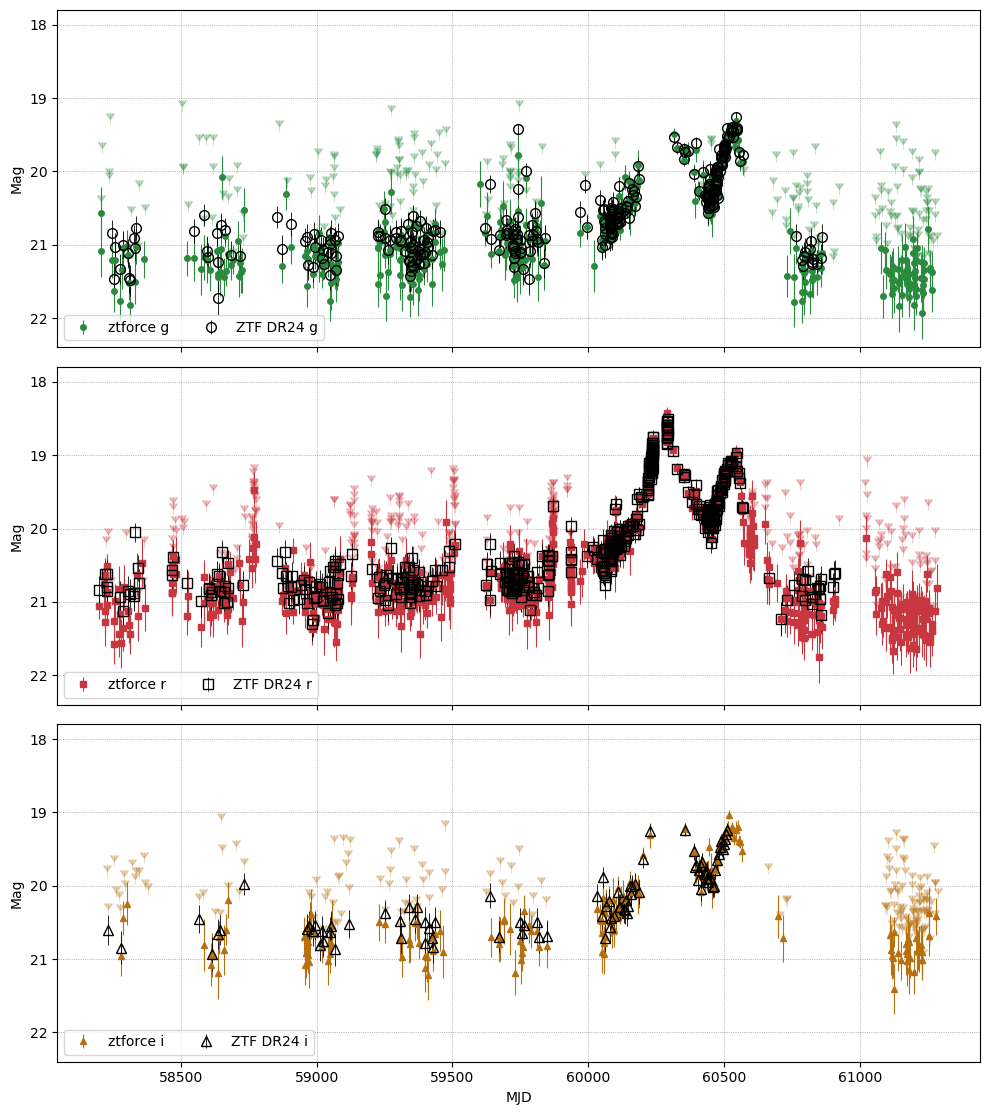

In [9]:
fig, axes = plt.subplots(len(lcs), 1, figsize=(10, 3.75 * len(lcs)), sharex=True)
for ax, (band, lc) in zip(axes, lcs.items(), strict=True):
    style = BAND_STYLE[band]
    plot_lightcurve(ax, lc.df, band, f"ztforce {band}")
    m = matched[band]
    ax.errorbar(
        m["obsjd"] - MJD_OFFSET,
        m["mag_ztf"],
        yerr=m["magerr"],
        fmt=style["marker"],
        ms=7,
        mfc="none",
        mec="k",
        ecolor="k",
        lw=0.6,
        label=f"ZTF DR24 {band}",
    )
    ax.set_ylim(22.4, 17.8)
    ax.set_ylabel("Mag")
    ax.grid(ls=":", lw=0.5, color="k", alpha=0.5)
    ax.legend(loc="lower left", ncol=2)
axes[-1].set_xlabel("MJD")
plt.tight_layout()
plt.show()

## 5. One-to-one comparison

ZTF DR24 magnitude against ztforce for every matched detection; the line is 1:1.

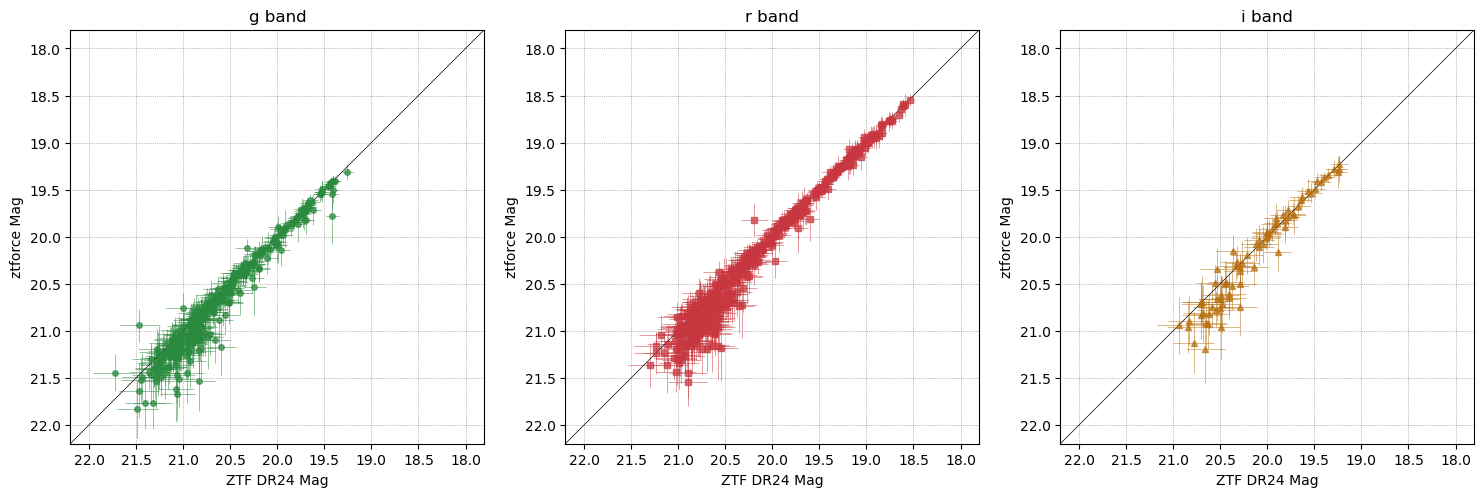

In [10]:
fig, axes = plt.subplots(1, len(lcs), figsize=(5 * len(lcs), 4.8))
for ax, band in zip(axes, lcs, strict=True):
    style = BAND_STYLE[band]
    m = matched[band][matched[band]["detection"]]
    ax.errorbar(
        m["mag_ztf"],
        m["mag"],
        xerr=m["magerr"],
        yerr=m["mag_err"],
        fmt=style["marker"],
        ms=4,
        lw=0.5,
        color=style["color"],
        alpha=0.7,
    )
    lo, hi = 17.8, 22.2
    ax.plot([lo, hi], [lo, hi], color="k", lw=0.5)
    ax.set_xlim(hi, lo)
    ax.set_ylim(hi, lo)
    ax.set_aspect("equal")
    ax.set_xlabel("ZTF DR24 Mag")
    ax.set_ylabel("ztforce Mag")
    ax.set_title(f"{band} band")
    ax.grid(ls=":", lw=0.5, color="k", alpha=0.5)
plt.tight_layout()
plt.show()

Brighter than about 20.5 mag the two agree to ~0.01 mag. Fainter than that, `ztforce` is ~0.1 mag fainter than DR24. The cause is the floating position: the DR24 lightcurve records an `ra`/`dec` for every detection, and as the supernova fades that centroid drifts toward the host nucleus 0.9″ away, from ~0.15″ off the SN position at 19–20 mag to ~0.8″ at 20.5–21 mag. The magnitude difference tracks the drift, so the catalog's free-position PSF fit is measuring a growing share of the galaxy core, while forced photometry stays on the supernova.

## 6. Binned lightcurve

`Lightcurve.rolling_stack` inverse-variance stacks all good epochs in a sliding window. With `step` equal to the window the bins do not overlap, so this is a 20-day binned lightcurve; each bin is a detection with `mag_stack` or carries a 5σ `upper_limit_stack`.

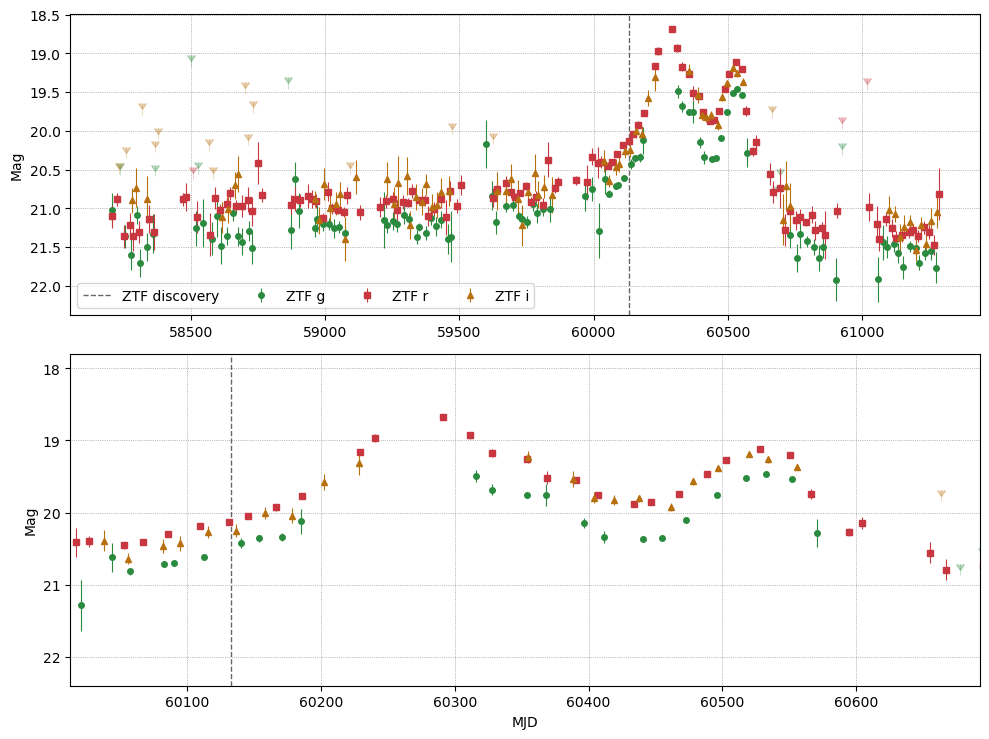

In [11]:
binned = {band: lc.rolling_stack(window=20, window_unit="days", step=20) for band, lc in lcs.items()}

fig, (ax_all, ax_sn) = plt.subplots(2, 1, figsize=(10, 7.5), gridspec_kw=dict(height_ratios=[1, 1.1]))
for band, b in binned.items():
    style = BAND_STYLE[band]
    mjd = b["obsjd_center"] - MJD_OFFSET
    det = b["detection"]
    for ax in (ax_all, ax_sn):
        ax.errorbar(
            mjd[det],
            b.loc[det, "mag_stack"],
            yerr=b.loc[det, "mag_err_stack"],
            fmt=style["marker"],
            ms=4,
            lw=0.8,
            color=style["color"],
            label=f"ZTF {band}",
        )
        ax.errorbar(
            mjd[~det],
            b.loc[~det, "upper_limit_stack"],
            yerr=0.15,
            uplims=True,
            fmt="none",
            lw=0.6,
            color=style["color"],
            alpha=0.3,
        )
for ax in (ax_all, ax_sn):
    ax.axvline(DISCOVERY_MJD, color="0.4", ls="--", lw=1, label="ZTF discovery")
    ax.invert_yaxis()
    ax.set_ylabel("Mag")
    ax.grid(ls=":", lw=0.5, color="k", alpha=0.5)
ax_all.legend(loc="lower left", ncol=4)
ax_sn.set_xlim(DISCOVERY_MJD - 120, DISCOVERY_MJD + 560)
ax_sn.set_ylim(22.4, 17.8)
ax_sn.set_xlabel("MJD")
plt.tight_layout()
plt.show()